# Power-law vs log-normal bias

Closure of the unbiasing for the two bias shapes (see `BIAS.md`), in the pT bins 100–140 and 140–180 GeV.

- **Observables:** $p_{\mathrm{T}}$, EEC, jet mass, $R_{\mathrm{g}}$, $k_{\mathrm{T}}$ and broadening, one figure per bias with both pT bins.
- **Panels:** biased, reweighted and unbiased distributions, and their ratio to the unbiased one.
- **Power-law:** $p = 8$, $d = 0.1$.
- **Log-normal `params1`:** peak at 112 / 152 GeV, $\sigma = 0.12$. The biased mean jet $p_{\mathrm{T}}$ goes down.
- **Log-normal `params2`:** peak at 128 / 168 GeV, $\sigma = 0.06$ (narrower). The biased mean jet $p_{\mathrm{T}}$ goes up.

The log-normal peak $p_{\mathrm{T}}^{\mathrm{peak}} = e^{\mu-\sigma^2}$ is where jets are most likely kept, and $\sigma$ is its width in $\ln p_{\mathrm{T}}$.

Inputs are the `../Output/files/unbias_weights_plots_*_<TAG>.root` files, with `TAG` set below. To make them, from `AnalysisCode/`:

```bash
UNBIAS_TAG=1M root -l -b -q 'driveBins.C("/path/to/MCOutput/")' && UNBIAS_TAG=1M ./runUnbiasing.sh && UNBIAS_TAG=1M ./runPlotUnbiasedWeights.sh
UNBIAS_TAG=1M UNBIAS_LN_PARAMS=params1 ./runLognormal.sh /path/to/MCOutput/   # same with params2
```

In [1]:
import os

import numpy as np
import uproot
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import plot_mpl as pm   # shared style and helpers

pm.use_tex_if_available()

True

In [2]:
# --- EDIT ---
TAG = "1M"   # sample tag = UNBIAS_TAG of the runs to compare (e.g. 10M, 50K)
FILES_DIR = "../Output/files"
SAVE = True   # also save every figure as PDF
PLOT_DIR = f"../Output/plots/mpl/comparison/{TAG}"

BINS = [(100, 140), (140, 180)]
P_LAW, D_LAW = 8, 0.1          # power-law bias parameters (driveBins.C)
LN_SETS = {                      # log-normal parameter sets (driveBinsLognormal.C): {bin low edge: peak pT [GeV]}, sigma
    "params1": ({100: 112, 140: 152}, 0.12),
    "params2": ({100: 128, 140: 168}, 0.06),
}
BIASES = {                       # name -> file-name part
    "powerlaw": "",
    "lognormal_params1": "_lognormal_params1",
    "lognormal_params2": "_lognormal_params2",
}


def bias_label(bias, lo, compact=False):
    # bias description with its parameter values (the peak of the log-normal depends on the pT bin)
    if bias == "powerlaw":   # parameters fixed (P_LAW, D_LAW), not written
        return "Power-law" if compact else "Power-law bias"
    peaks, sigma = LN_SETS[bias.split("_", 1)[1]]
    peak, width = rf"$p_{{\mathrm{{T}}}}^{{\mathrm{{peak}}}} = {peaks[lo]}$ GeV", rf"$\sigma = {sigma:g}$"
    return "Log-normal\n" + peak + "\n" + width if compact else "Log-normal bias,\n" + peak + ", " + width

# Histogram binning per observable (the plots merge the bins saved by plot_unbias_weights):
#   int k        -> merge every k adjacent bins
#   list of edges -> custom bins; every edge must be one of the original bin edges
#   None / absent -> original binning
# Original: pt 80 bins of 0.5 GeV, eec 60 log bins in 0.004-0.4, jet_mass 30, rg 13, kt 20, broadening 25.
REBIN = {
    "pt": 4,      # 20 bins of 2 GeV
    "eec": 2,     # 30 log bins
    # "jet_mass": 2,
    # "kt": [0, 2, 4, 6, 8, 10, 14, 20, 30, 40],
}


In [3]:
# observable -> (histogram stem in the ROOT file, x label, log x, legend position)
OBSERVABLES = {
    "pt":         ("",       r"$p_{\mathrm{T}}$ [GeV]",           False, "upper right"),
    "eec":        ("_eec",   r"$\theta$",                         True,  "lower right"),
    "jet_mass":   ("_mass",  r"$M_{\mathrm{jet}}$ [GeV]",         False, "upper right"),
    "rg":         ("_rg",    r"$R_{\mathrm{g}}$",                 False, "upper right"),
    "kt":         ("_kt",    r"$k_{\mathrm{T}}$ [GeV]",           False, "upper right"),
    "broadening": ("_broad", r"$\lambda_{1}$",       False, "upper right"),
}


# observable -> figure title
OBS_TITLE = {
    "pt":         r"Jet $p_{\mathrm{T}}$",
    "eec":        "EEC",
    "jet_mass":   "Jet mass",
    "rg":         r"Groomed radius $R_{\mathrm{g}}$",
    "kt":         r"Groomed $k_{\mathrm{T}}$",
    "broadening": r"Broadening $\lambda_{1}$",
}


def rebin(h, spec):
    # merge bins of a pm.Hist: spec = merge factor (int) or list of edges (subset of h.edges)
    if spec is None:
        return h
    if isinstance(spec, int):
        starts = np.arange(0, len(h.values), spec)
        return pm.Hist(np.append(h.edges[starts], h.edges[-1]),
                       np.add.reduceat(h.values, starts),
                       np.sqrt(np.add.reduceat(h.errors ** 2, starts)))
    pos = []
    for e in spec:
        m = np.flatnonzero(np.isclose(h.edges, e, rtol=1e-9, atol=1e-12))
        if not m.size:
            raise ValueError(f"rebin: edge {e} is not one of the original bin edges")
        pos.append(int(m[0]))
    pos = np.array(pos)
    starts = pos[:-1]
    ends = pos[1:]
    csum_v = np.concatenate([[0.0], np.cumsum(h.values)])
    csum_e = np.concatenate([[0.0], np.cumsum(h.errors ** 2)])
    return pm.Hist(h.edges[pos], csum_v[ends] - csum_v[starts], np.sqrt(csum_e[ends] - csum_e[starts]))


def load(bias, lo, hi, tag=None):
    # {observable: (biased, reweighted, unbiased, y label)} for one bias type and pT bin
    return load_file(f"{FILES_DIR}/unbias_weights_plots_{lo}_{hi}{BIASES[bias]}_{tag or TAG}.root")


def load_file(path):
    # {observable: (biased, reweighted, unbiased, y label)} from one unbias_weights_plots file
    out = {}
    with uproot.open(path) as f:
        keys = {k.split(";")[0] for k in f.keys()}
        for obs, (stem, *_rest) in OBSERVABLES.items():
            names = [f"h{stem}_{s}" for s in ("base", "total", "target")]
            if set(names) <= keys:
                hists = [rebin(pm.Hist.from_root(f[n]), REBIN.get(obs)) for n in names]
                out[obs] = (*hists, "EEC" if obs == "eec" else pm.y_title(f[names[2]]))
    return out


data = {(b, lo, hi): load(b, lo, hi) for b in BIASES for lo, hi in BINS}
print("loaded:", ", ".join(f"{b} {lo}-{hi}" for b, lo, hi in data))

loaded: powerlaw 100-140, powerlaw 140-180, lognormal_params1 100-140, lognormal_params1 140-180, lognormal_params2 100-140, lognormal_params2 140-180


In [4]:
def compare(obs, bias, fill="partly"):
    # one figure for one observable, one bias type and one fill-up of the biased sample
    # (partly / fully biased, see the mean jet pT section): the pT bins side by side
    d = data if fill == "partly" else data_full
    _stem, xlabel, logx, _ = OBSERVABLES[obs]
    fig = plt.figure(figsize=(7.6, 4.2), layout="constrained")
    cells = fig.subfigures(1, len(BINS), squeeze=False)[0]
    for c, (lo, hi) in enumerate(BINS):
        if obs not in d[(bias, lo, hi)]:
            cells[c].set_visible(False)
            continue
        hb, ht, hg, ylabel = d[(bias, lo, hi)][obs]
        a, b = cells[c].subplots(2, 1, sharex=True, height_ratios=[3, 1])
        pm.draw_ratio_plot(a, b, hb, ht, hg, xlabel, ylabel, logx=logx, logy=True,
                           target_name="", legend_loc=None, label=None, bands_only=True)
        # inside the panels: legend top left (left panel), bin / bias label top right (both panels)
        if c == 0:
            a.legend(*pm.legend_handles(""), loc="upper left", ncol=1, fontsize="medium", frameon=False)
        # pT bin, then the bias (log-normal: with its peak, which depends on the bin)
        label = pm.bin_label(lo, hi) + "\n" + ("Power-law bias" if bias == "powerlaw" else "Log-normal bias")
        label += ", fully biased" if fill == "fully" else ""
        if bias != "powerlaw":
            label += "\n" + bias_label(bias, lo).split("\n", 1)[1]
        a.text(0.96, 0.94, label, transform=a.transAxes,
               va="top", ha="right", multialignment="right", fontsize="small")
        # headroom: keep the data below the label
        frac = 0.6
        ymin, _ = a.get_ylim()
        vals = np.concatenate([h.values for h in (hb, ht, hg)])
        vmax = vals[np.isfinite(vals)].max()
        a.set_ylim(ymin, 10 ** (np.log10(ymin) + (np.log10(vmax) - np.log10(ymin)) / frac))
    if SAVE:
        os.makedirs(PLOT_DIR, exist_ok=True)
        fig.savefig(f"{PLOT_DIR}/compare_{obs}_{bias}{'_fully' if fill == 'fully' else ''}.pdf", bbox_inches="tight")
    plt.show()

## Jet $p_{\mathrm{T}}$

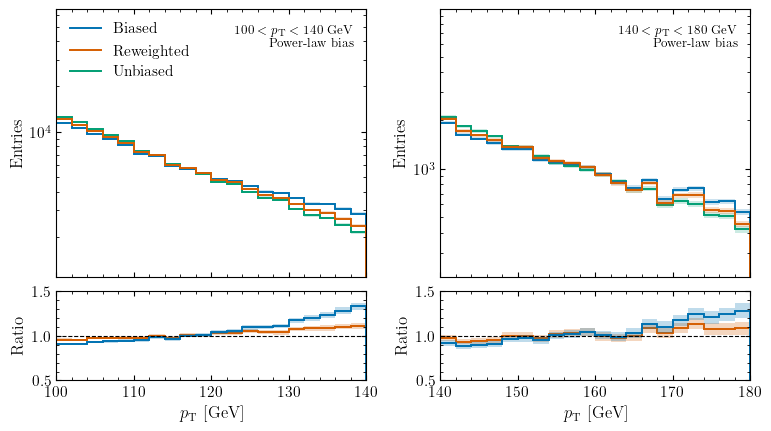

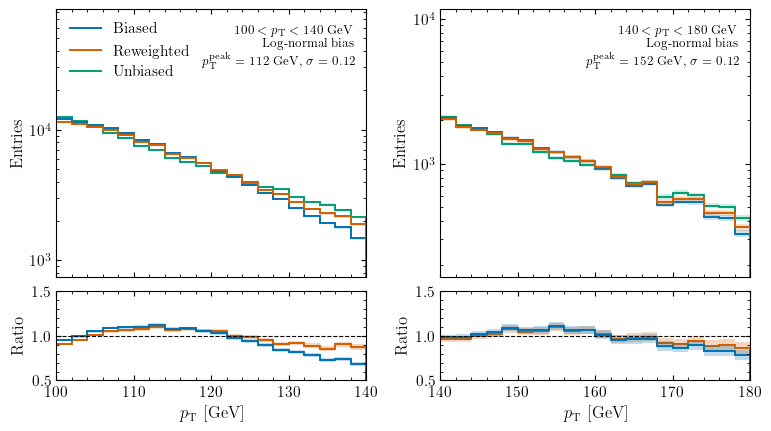

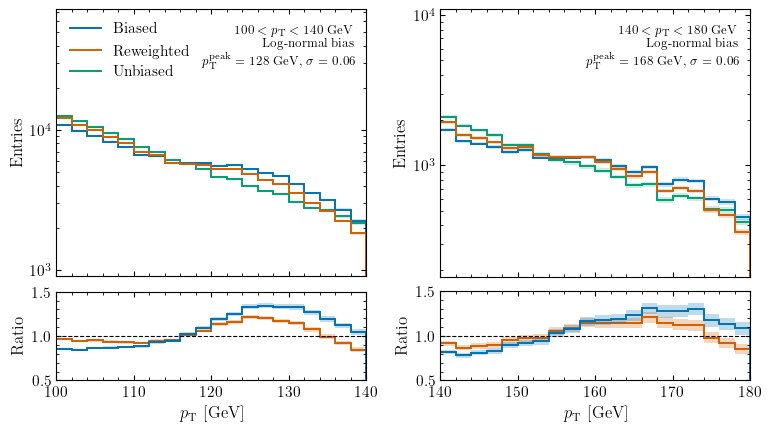

In [5]:
compare("pt", "powerlaw")
compare("pt", "lognormal_params1")
compare("pt", "lognormal_params2")

## EEC

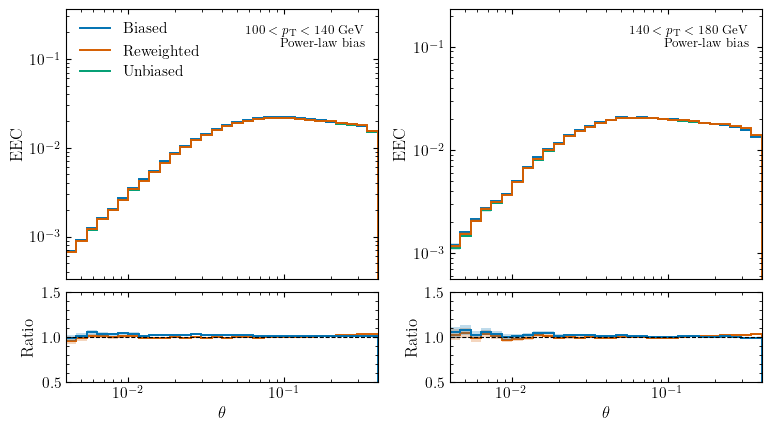

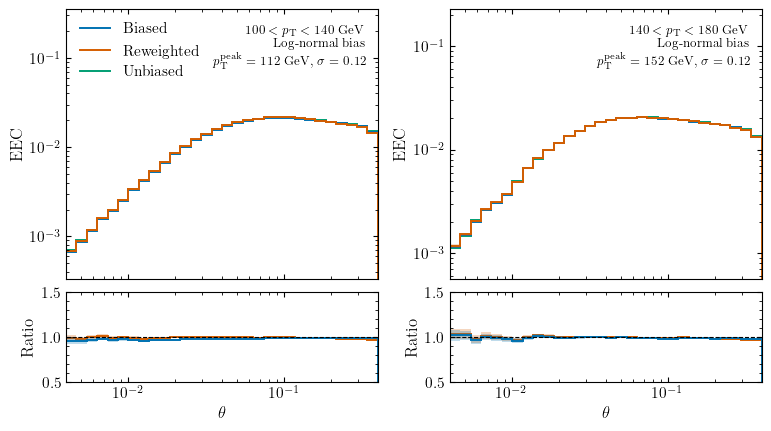

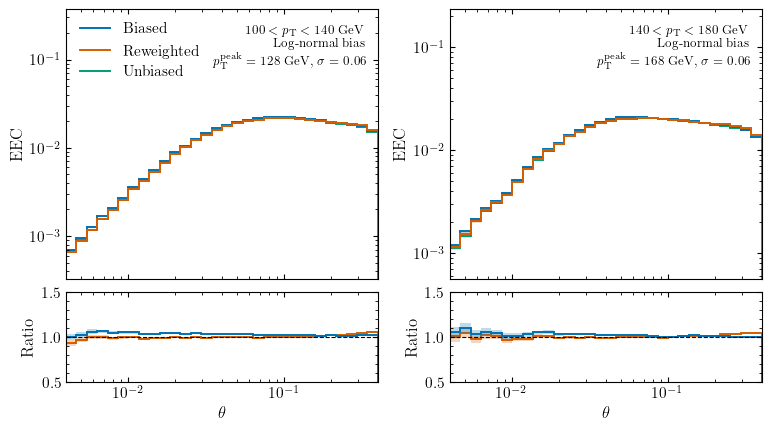

In [6]:
compare("eec", "powerlaw")
compare("eec", "lognormal_params1")
compare("eec", "lognormal_params2")

## Jet mass

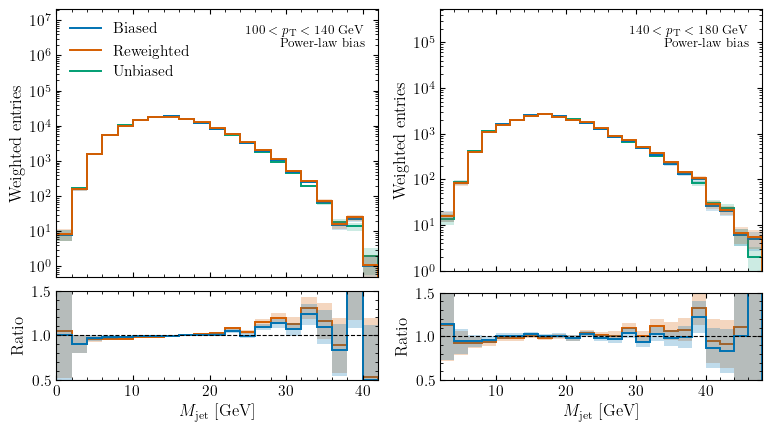

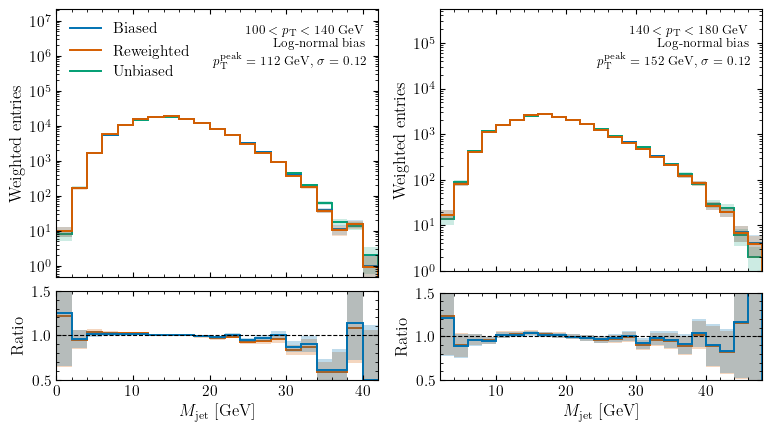

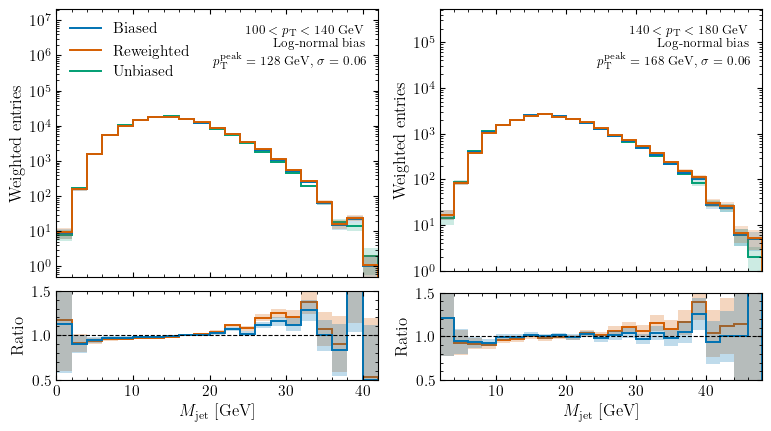

In [7]:
compare("jet_mass", "powerlaw")
compare("jet_mass", "lognormal_params1")
compare("jet_mass", "lognormal_params2")

## Groomed radius $R_{\mathrm{g}}$

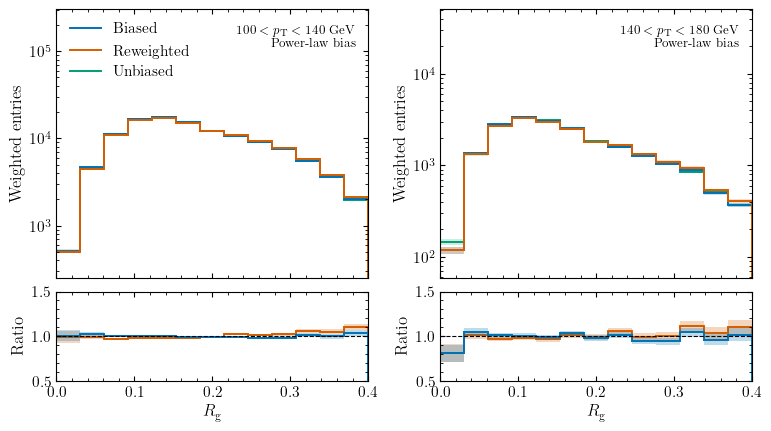

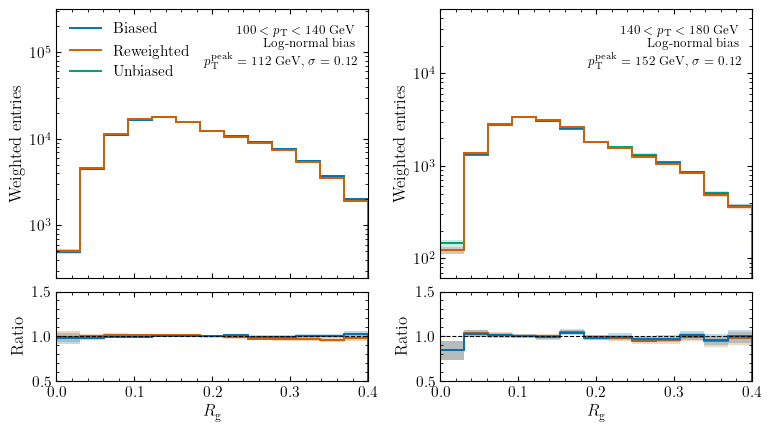

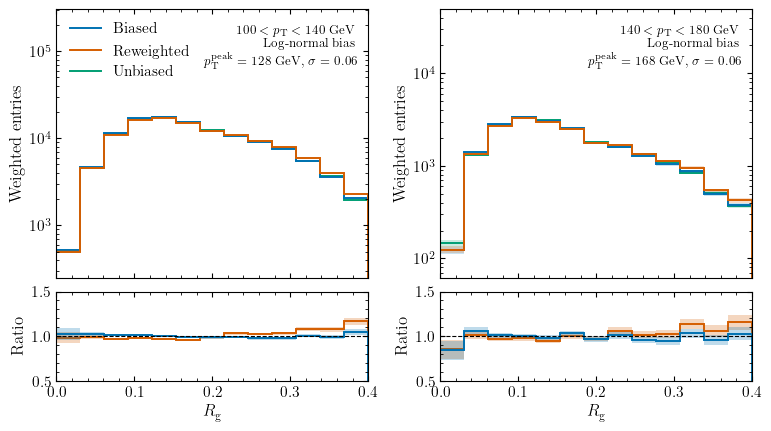

In [8]:
compare("rg", "powerlaw")
compare("rg", "lognormal_params1")
compare("rg", "lognormal_params2")

## Groomed $k_{\mathrm{T}}$

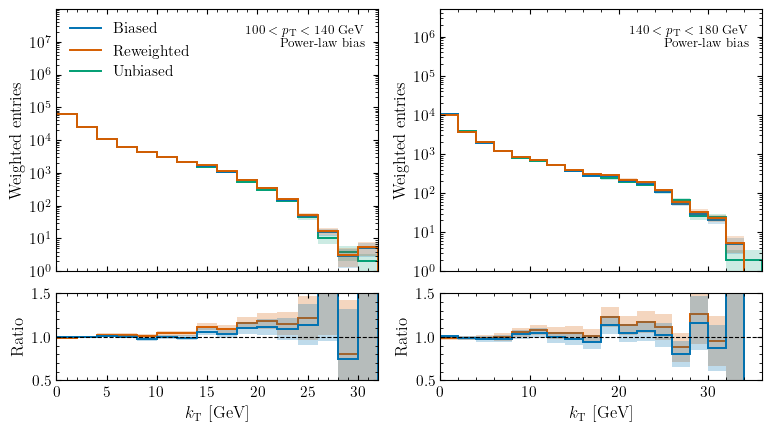

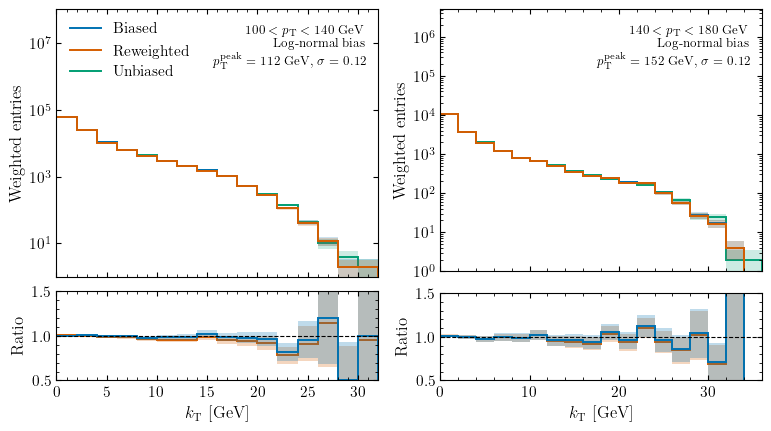

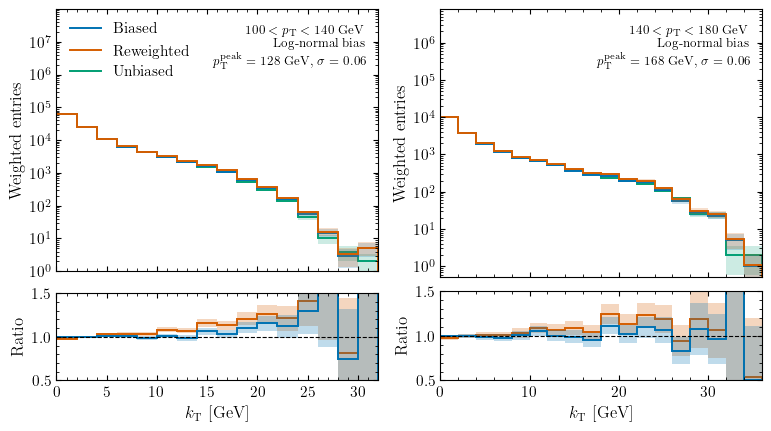

In [9]:
compare("kt", "powerlaw")
compare("kt", "lognormal_params1")
compare("kt", "lognormal_params2")

## Broadening

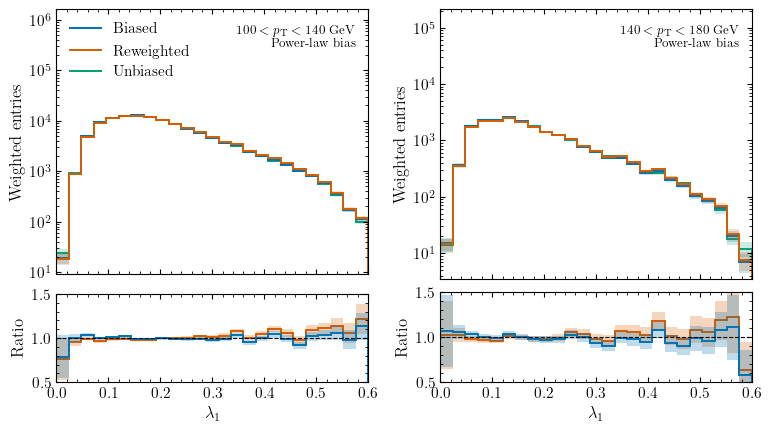

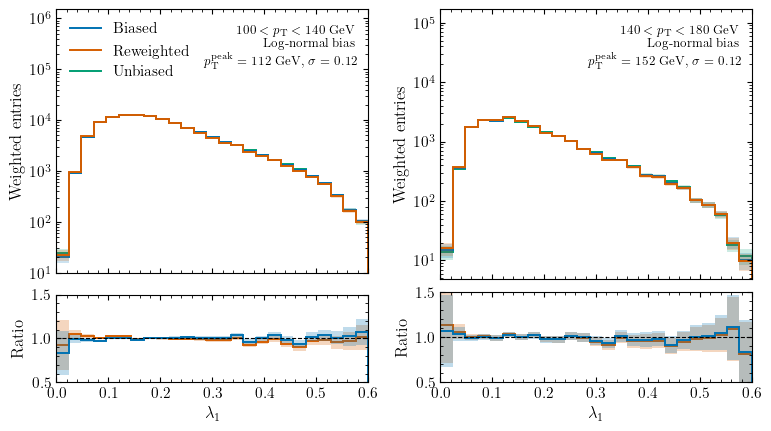

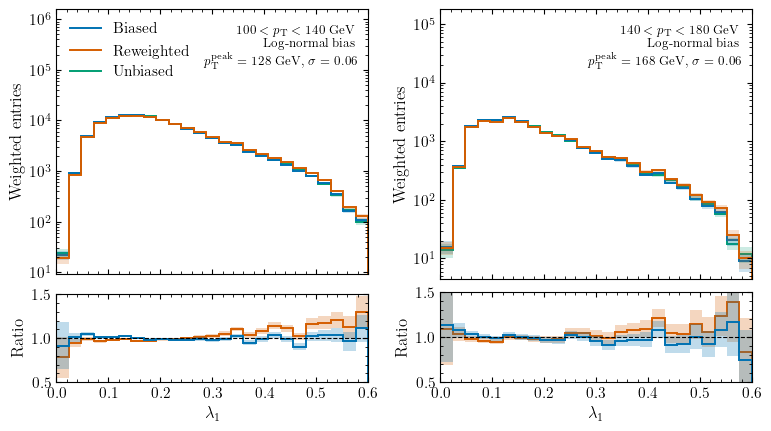

In [10]:
compare("broadening", "powerlaw")
compare("broadening", "lognormal_params1")
compare("broadening", "lognormal_params2")

## Mean jet $p_{\mathrm{T}}$ per bin

Mean jet $p_{\mathrm{T}}$ in each pT bin minus the unbiased one, for each bias (columns), with the partly biased sample only (see below).

- **Biased:** $q_{\mathrm{AA}}$, the biased sample.
- **Reweighted:** $w\,q_{\mathrm{AA}}$, the biased sample with the unbiasing weights.
- **Unbiased:** $q_{\mathrm{pp}}$, the reference sample, the line at 0.

The values and their errors are in the printed table.

bias                 mode  bin              biased     reweighted       unbiased  biased-unbiased  reweighted-unbiased
powerlaw             0     100-140    115.15+-0.03   114.52+-0.03   114.09+-0.03      +1.06+-0.05          +0.43+-0.04
powerlaw             0     140-180    155.97+-0.08   155.35+-0.08   154.88+-0.08      +1.09+-0.11          +0.47+-0.11
lognormal_params1    0     100-140    113.33+-0.03   113.91+-0.03   114.09+-0.03      -0.76+-0.04          -0.18+-0.04
lognormal_params1    0     140-180    154.35+-0.07   154.62+-0.07   154.88+-0.08      -0.53+-0.10          -0.25+-0.11
lognormal_params2    0     100-140    115.71+-0.03   114.65+-0.03   114.09+-0.03      +1.63+-0.04          +0.57+-0.04
lognormal_params2    0     140-180    156.65+-0.08   155.64+-0.07   154.88+-0.08      +1.77+-0.11          +0.76+-0.11


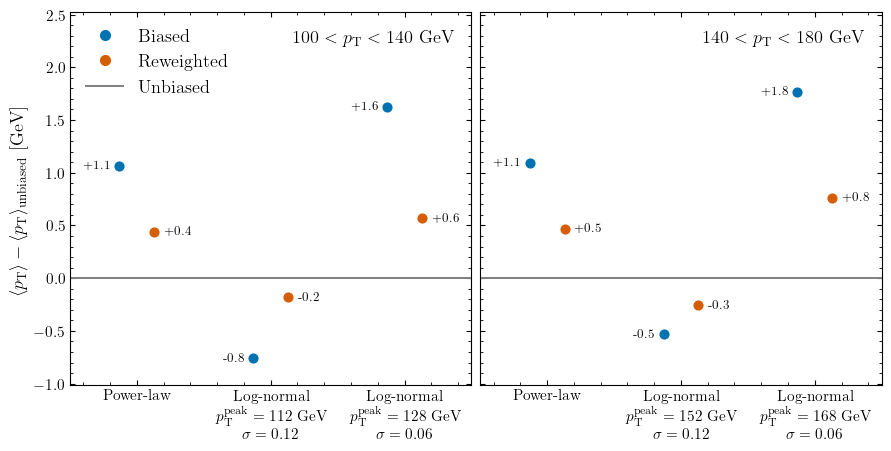

In [11]:
MEAN_BIASES = ["powerlaw", "lognormal_params1", "lognormal_params2"]   # one column each


def mean_pt(h):
    # weighted mean of the bin centres and its statistical error
    c = 0.5 * (h.edges[:-1] + h.edges[1:])
    s = h.values.sum()
    mu = (h.values * c).sum() / s
    return mu, np.sqrt((h.errors ** 2 * (c - mu) ** 2).sum()) / s


def mean_pts(modes, biases=None, bins=None, parts=None):
    # modes: {mode: (sample tag, label, marker, filled)}; biases (columns), bins (panels) and
    # parts ({bias: file-name part}) default to MEAN_BIASES, BINS and BIASES
    # -> {(bias, mode, lo, hi): {"base"|"total"|"target": (mean, error)}} for every file that exists
    out = {}
    for bias in biases or MEAN_BIASES:
        for mode, (tag, *_rest) in modes.items():
            for lo, hi in bins or BINS:
                path = f"{FILES_DIR}/unbias_weights_plots_{lo}_{hi}{(parts or BIASES)[bias]}_{tag}.root"
                if not os.path.exists(path):
                    print("missing:", path)
                    continue
                with uproot.open(path) as f:
                    out[(bias, mode, lo, hi)] = {s: mean_pt(pm.Hist.from_root(f[f"h_{s}"]))
                                                 for s in ("base", "total", "target")}
    return out


def print_means(means):
    print(f"{'bias':20} {'mode':5} {'bin':8} {'biased':>14} {'reweighted':>14} {'unbiased':>14}"
          f" {'biased-unbiased':>16} {'reweighted-unbiased':>20}")
    for (bias, mode, lo, hi), m in means.items():
        (mb, eb), (mt, et), (mg, eg) = m["base"], m["total"], m["target"]
        print(f"{bias:20} {mode:5} {lo}-{hi:<4} {mb:8.2f}+-{eb:.2f} {mt:8.2f}+-{et:.2f} {mg:8.2f}+-{eg:.2f}"
              f" {mb - mg:+10.2f}+-{np.hypot(eb, eg):.2f} {mt - mg:+14.2f}+-{np.hypot(et, eg):.2f}")


def plot_mean_shift(means, modes, name, biases=None, bins=None, xlabel=None, headroom=None, separators=False):
    # <pT> - <pT>_unbiased per column (bias type), one panel per pT bin. Colour = sample (biased left,
    # reweighted right of the column centre); marker = mode (two modes: on the same vertical line).
    # Markers only (no error bars; the errors are in the printed table), each with its value:
    # biased values to the left, reweighted to the right. Inside, without frames: samples legend
    # (left panel), modes legend (right panel, if several), pT bin (top right of each panel).
    # biases (columns) and bins (panels) default to MEAN_BIASES and BINS; xlabel(bias, lo) gives the
    # column labels (default: bias_label); headroom = space above the points for the legends, as a
    # fraction of the y range (default 0.3, 0.45 for more than two modes); separators: no x ticks at the
    # columns, one tick between neighbouring columns instead
    if not means:
        print("nothing to plot")
        return
    biases, bins = biases or MEAN_BIASES, bins or BINS
    xlabel = xlabel or (lambda b, lo: bias_label(b, lo, compact=True))
    nm = len(modes)
    centre = {"base": -0.13, "total": 0.13} if nm <= 2 else {"base": -0.17, "total": 0.17}
    step = 0.0 if nm <= 2 else 0.06
    ms = 6 if nm <= 2 else 5
    COLOR = {"base": pm.C_BASE, "total": pm.C_TOTAL}
    fig, axes = plt.subplots(1, len(bins), figsize=(8.8 if nm <= 2 else 9.6, 4.4),
                             sharey=True, layout="constrained")
    shifts = [m[s][0] - m["target"][0] for m in means.values() for s in ("base", "total")]
    span = max(max(shifts), 0) - min(min(shifts), 0)
    # headroom at the top for the legends and the pT bin
    ylim = (min(min(shifts), 0) - 0.1 * span, max(max(shifts), 0) + (headroom or (0.3 if nm <= 2 else 0.45)) * span)
    for ax, (lo, hi) in zip(axes, bins):
        ax.axhline(0, color="0.5", lw=1.4)
        for i, bias in enumerate(biases):
            for s in ("base", "total"):
                pts = []   # (x, y) of this sample in this column
                for j, (mode, (_tag, _label, marker, filled)) in enumerate(modes.items()):
                    if (bias, mode, lo, hi) not in means:
                        continue
                    m = means[(bias, mode, lo, hi)]
                    x, y = i + centre[s] + (j - (nm - 1) / 2) * step, m[s][0] - m["target"][0]
                    ax.plot(x, y, marker=marker, ms=ms, ls="", color=COLOR[s],
                            mfc=COLOR[s] if filled else "white", mew=1.3, zorder=3)
                    pts.append((x, y))
                # value labels: biased to the left, reweighted to the right; labels of points
                # closer than ~6% of the y range are pushed apart vertically
                left = s == "base"
                order = sorted(range(len(pts)), key=lambda k: pts[k][1])
                for rank, k in enumerate(order):
                    x, y = pts[k]
                    dy = 0
                    if len(pts) > 1:
                        near = [q for q in range(len(pts)) if q != k and abs(pts[q][1] - y) < 0.06 * span]
                        if near:
                            dy = 5 if rank > order.index(near[0]) else -5
                    ax.annotate(f"{y:+.1f}", (x, y), xytext=(-7 if left else 7, dy), textcoords="offset points",
                                ha="right" if left else "left", va="center", fontsize="small")
        ax.set_xticks(range(len(biases)), [xlabel(b, lo) for b in biases], fontsize="medium")
        ax.set_xlim(-0.5, len(biases) - 0.5)
        if separators:
            ax.set_xticks([i + 0.5 for i in range(len(biases) - 1)], minor=True)
            ax.tick_params(axis="x", which="major", length=0)
            ax.tick_params(axis="x", which="minor", length=plt.rcParams["xtick.major.size"])
        ax.set_ylim(*ylim)
        ax.text(0.96, 0.95, pm.bin_label(lo, hi), transform=ax.transAxes, ha="right", va="top", fontsize="large")
    axes[0].set_ylabel(r"$\langle p_{\mathrm{T}}\rangle - \langle p_{\mathrm{T}}\rangle_{\mathrm{unbiased}}$ [GeV]", fontsize="large")
    for ax in axes:
        ax.tick_params(axis="y", labelsize="medium")
    LEG = dict(loc="upper left", fontsize="large", frameon=False)
    axes[0].legend([Line2D([], [], color=pm.C_BASE, marker="o", ms=7, ls=""),
                    Line2D([], [], color=pm.C_TOTAL, marker="o", ms=7, ls=""),
                    Line2D([], [], color="0.5", lw=1.4)],
                   ["Biased", "Reweighted", "Unbiased"], **LEG)
    if nm > 1:
        axes[-1].legend([Line2D([], [], color="0.3", marker=mk, ms=7, ls="", mfc="0.3" if fl else "white", mew=1.3)
                         for _t, _l, mk, fl in modes.values()],
                        [lab for _t, lab, _m, _f in modes.values()], **LEG)
    if SAVE:
        os.makedirs(PLOT_DIR, exist_ok=True)
        fig.savefig(f"{PLOT_DIR}/{name}.pdf", bbox_inches="tight")
    plt.show()


# original construction only (fillMode 0)
ORIGINAL = {"0": (TAG, "Partly biased", "o", True)}
means = mean_pts(ORIGINAL)
print_means(means)
plot_mean_shift(means, ORIGINAL, "mean_pt_shift")

## Mean jet $p_{\mathrm{T}}$: jet quenching log-normal bias

Mean jet $p_{\mathrm{T}}$ in each window minus the unbiased one, for the jet quenching log-normal bias (see `BIAS.md`), one column per parameter set. Every jet loses an energy $\epsilon$ and the window is cut on $p_{\mathrm{T}}-\epsilon$.

- **Biased:** the jets with $p_{\mathrm{T}}-\epsilon$ in the window, with their true $p_{\mathrm{T}}$.
- **Reweighted:** the biased sample with the unbiasing weights.
- **Unbiased:** the jets with the true $p_{\mathrm{T}}$ in the window, the line at 0.


bias                 mode  bin              biased     reweighted       unbiased  biased-unbiased  reweighted-unbiased
out                  q     100-200    136.73+-0.04   134.04+-0.04   122.42+-0.03     +14.31+-0.05         +11.62+-0.04
out                  q     150-250    191.61+-0.11   186.28+-0.09   177.11+-0.08     +14.50+-0.14          +9.16+-0.12
in                   q     100-200    128.22+-0.03   125.34+-0.03   122.42+-0.03      +5.80+-0.04          +2.92+-0.04
in                   q     150-250    182.77+-0.09   179.86+-0.08   177.11+-0.08      +5.65+-0.12          +2.74+-0.11


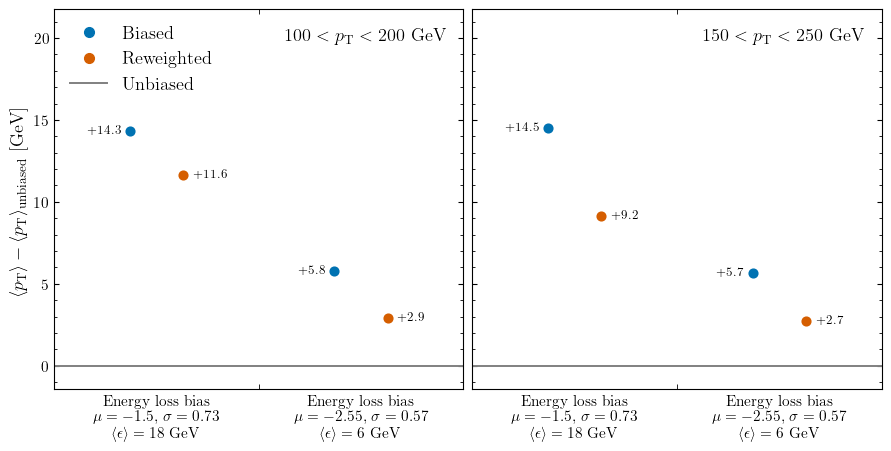

In [12]:
QUENCH_TAG = "4M_hipt"                       # UNBIAS_TAG of the runQuench.sh runs
QUENCH_BINS = [(100, 200), (150, 250)]       # windows of driveBinsQuench.C
QUENCH_SETS = {                              # set -> (mu, sigma), Table 1 of the paper
    "out": (-1.5, 0.73),
    "in":  (-2.55, 0.57),
}
QUENCH_OMEGAC = 62.5                         # GeV, UNBIAS_QUENCH_OMEGAC
QUENCH_BIASES = list(QUENCH_SETS)
QUENCH_PARTS = {s: f"_quench_{s}" for s in QUENCH_SETS}


def quench_label(bias, lo):
    mu, sigma = QUENCH_SETS[bias]
    mean = QUENCH_OMEGAC * np.exp(mu + sigma ** 2 / 2)
    return "Energy loss bias\n" + rf"$\mu = {mu:g}$, $\sigma = {sigma:g}$" + "\n" + rf"$\langle\epsilon\rangle = {mean:.0f}$ GeV"


QUENCH = {"q": (QUENCH_TAG, "Quenched", "o", True)}
means_quench = mean_pts(QUENCH, biases=QUENCH_BIASES, bins=QUENCH_BINS, parts=QUENCH_PARTS)
print_means(means_quench)
plot_mean_shift(means_quench, QUENCH, "mean_pt_shift_quench", biases=QUENCH_BIASES, bins=QUENCH_BINS,
                xlabel=quench_label, headroom=0.5, separators=True)


## Mean jet $p_{\mathrm{T}}$: partly vs fully biased

The same plot for two ways of building the reference $q_{\mathrm{pp}}$ and the biased sample $q_{\mathrm{AA}}$ from the jets $\phi$ in the bin. The bias is the same in both: a jet is kept with probability $w_{\mathrm{bias}}(p_{\mathrm{T}})$, and $k$ is the fraction kept.

- **Partly biased:** every jet is used twice, $\phi_X = \phi_Y$. $q_{\mathrm{pp}} = q(\phi_X \cup \phi_Y)$ and $q_{\mathrm{AA}} = q(\phi_X^{\mathrm{kept}} \cup \phi_{Y'})$, with $Y'$ drawn from $Y$ up to the size of $q_{\mathrm{pp}}$. Biased/unbiased $= (w_{\mathrm{bias}}+2-k)/2$.
- **Fully biased:** $q_{\mathrm{pp}} = q(\phi)$, all jets, and $q_{\mathrm{AA}} = q(\phi^{\mathrm{kept}})$. Biased/unbiased $= w_{\mathrm{bias}}/k$.

These are `fillMode` 0 and 1 (`BIAS.md`), set with `UNBIAS_FILL`, with tags `1M` and `1M_downsampled`, e.g.

```bash
UNBIAS_FILL=1 UNBIAS_TAG=1M_downsampled UNBIAS_LN_PARAMS=params1 ./runLognormal.sh /path/to/MCOutput/
```

bias                 mode  bin              biased     reweighted       unbiased  biased-unbiased  reweighted-unbiased
powerlaw             0     100-140    115.15+-0.03   114.52+-0.03   114.09+-0.03      +1.06+-0.05          +0.43+-0.04
powerlaw             0     140-180    155.97+-0.08   155.35+-0.08   154.88+-0.08      +1.09+-0.11          +0.47+-0.11
powerlaw             1     100-140    121.77+-0.09   114.73+-0.09   114.09+-0.04      +7.69+-0.10          +0.64+-0.10
powerlaw             1     140-180    162.18+-0.20   155.64+-0.21   154.88+-0.11      +7.30+-0.22          +0.76+-0.24
lognormal_params1    0     100-140    113.33+-0.03   113.91+-0.03   114.09+-0.03      -0.76+-0.04          -0.18+-0.04
lognormal_params1    0     140-180    154.35+-0.07   154.62+-0.07   154.88+-0.08      -0.53+-0.10          -0.25+-0.11
lognormal_params1    1     100-140    112.24+-0.04   113.62+-0.06   114.09+-0.04      -1.85+-0.06          -0.46+-0.07
lognormal_params1    1     140-180    153.50+-0.

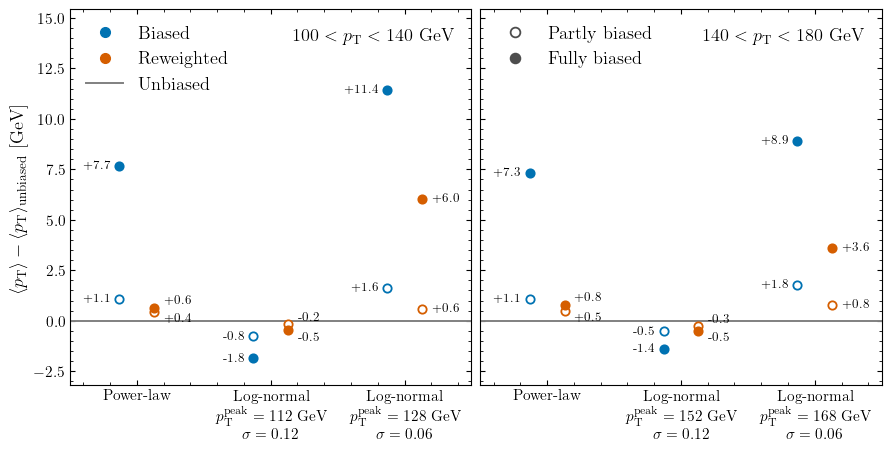

In [13]:
# mode -> (sample tag, legend label, marker, filled)
MODES = {
    "0": (TAG,                 "Partly biased", "o", False),
    "1": (f"{TAG}_downsampled", "Fully biased",  "o", True),
}
means_modes = mean_pts(MODES)
print_means(means_modes)
plot_mean_shift(means_modes, MODES, "mean_pt_shift_modes")